# Slide Catalogue and Whole-Slide Images

**C-Stroke · case HB02CV · reference notebook 1 of 4**

C-Stroke is a post-mortem study of one human brain after an ischaemic stroke (case HB02CV). The brain was cut into five tissue **blocks**, each a slab along the left–right axis. Every block was sectioned at 20 µm into near-sagittal sections, and the sections were stained in interleaved series:

| Stain | Code | What it shows |
|---|---|---|
| Immunohistochemistry | `IHC` | One protein marker per slide (CD68, GFAP, CD34, HIF1α, fibrinogen, APP, GAP43, AQP4), detected with the brown DAB chromogen |
| Nissl | `N` | Cell bodies (cytoarchitecture) |
| H&E | `HE` | General tissue morphology; the infarct is outlined on these slides |
| Myelin | `M` | Myelinated fibres (white matter) |

All slides of a block are registered to one 192,000 × 192,000 pixel canvas, so the same coordinate points at the same tissue on every stain. This notebook shows how to find slides and read their images programmatically:

1. Explore the catalogue: blocks, stains, markers, and the *sets* that group neighbouring sections.
2. Find slides and their neighbours on other stains.
3. Read whole sections, regions and full-resolution fields from the image pyramid.
4. Compare the same location across the four stains.
5. Use the block-face photographs taken during sectioning.
6. Cut sections into tiles for analysis, and export a download table.

The helpers used here are `SlideCatalog` and `SlideHelper` from `slide_utils.py`, with plotting functions from `display_utils.py`. The other reference notebooks build on them: `pathology_annotations.ipynb` (annotations), `lesion_across_sections.ipynb` (lesion measurements along the blocks) and `mri_reference_space.ipynb` (MRI and its link to the sections).

**Runtime:** a few minutes on a CPU (Colab, Kaggle or local). No GPU or credentials are required.

## 1. Setup

The notebook uses the helper modules of this repository. In a local clone they are found automatically. On Google Colab, Kaggle or any other fresh environment, the cell below clones the repository first. All data are read from the C-Stroke platform at `https://c-stroke.humanbrain.in` and cached under `~/.cache/cstroke`.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/24f2007780/stroke_utils.git"

# Use the local repository (this notebook's parent folder) if present; otherwise clone it.
root = next((p for p in (Path.cwd(), Path.cwd().parent, Path.cwd() / "stroke_utils")
             if (p / "slide_utils.py").exists()), None)
if root is None:
    subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    root = Path.cwd() / "stroke_utils"
sys.path.insert(0, str(root))
print("Helper modules from", root)

Helper modules from /home/antareep/workspace/stroke_notebook/stroke_utils


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scipy import ndimage as ndi

import display_utils as du
from slide_utils import BLOCKS, MARKERS, MPP_LEVEL0, STAINS, SlideCatalog, SlideHelper, tissue_mask

du.set_style()
pd.set_option("display.max_colwidth", 50)

# Worked example used throughout: a set from block 313 whose four sections lie within 60 um of each other.
EXAMPLE_SET = 170

## 2. The slide catalogue

`SlideCatalog` reads the platform's catalogue and offers two tables:

* `catalog.slides` lists every distinct slide (block, stain, section);
* `catalog.entries` lists the slides of every **set**. A set anchors one IHC section and adds the nearest Nissl, H&E and myelin sections of the same block, with their offset in mm. These are the groups the platform's viewer shows side by side.

In [3]:
catalog = SlideCatalog()
print(catalog)
catalog.slides.head()

SlideCatalog(505 sets, 1124 slides, blocks [217, 218, 313, 314, 315])


,block,section,stain,marker,path,annotation_url,annotation_type,z_mm,global_id
0,217,176,HE,None,/stroke2d/storageIIT/586/HEOS/B_586_HB2CV[RTM]...,None,None,121.34,6067
1,217,194,HE,None,/stroke2d/storageIIT/586/HEOS/B_586_HB2CV[RTM]...,None,None,120.98,6049
2,217,224,HE,None,/stroke2d/storageIIT/586/HEOS/B_586_HB2-CV-[RT...,None,None,120.38,6019
3,217,236,HE,None,/stroke2d/storageIIT/586/HEOS/B_586_HB2CV[RTM]...,None,None,120.14,6007
4,217,248,HE,None,/stroke2d/storageIIT/586/HEOS/B_586_HB2CV[RTM]...,None,None,119.90,5995


### 2.1 Blocks and stains

`summary()` gives one row per block: its position in the brain, the range of section numbers, the number of slides per stain, and how many slides carry an annotation (IHC marker regions, or the infarct on H&E).

In [4]:
catalog.summary()

stain,position,sections,Immunohistochemistry,Nissl,H&E,Myelin,annotated IHC,infarct-annotated H&E
block,,,,,,,,
217,right medial,95-1661,102,22,43,17,91,0
218,right lateral,295-1896,150,54,57,35,106,0
313,left medial,47-1787,107,67,49,55,105,39
314,left lateral,182-1466,100,68,51,17,95,46
315,left mid,188-1019,46,37,34,13,44,29


### 2.2 Where the slides lie along each block

Section numbers count 20 µm steps along a block, so `section × 0.02` is the position in mm. The figure shows each block as four lanes, one per stain, with a tick for every slide. IHC ticks are coloured by marker. Darker lanes are more densely sampled; gaps show where a stain was not cut or not scanned.

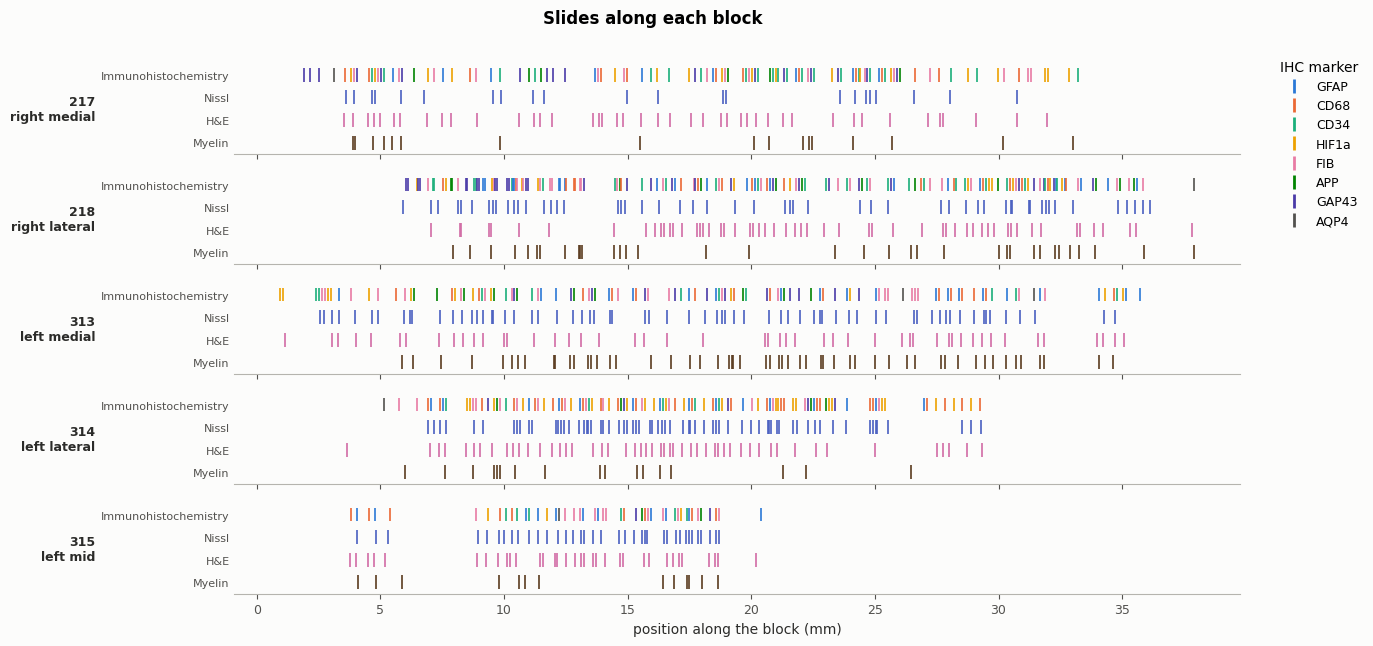

In [5]:
fig, axes = plt.subplots(len(catalog.blocks), 1, figsize=(14, 1.15 * len(catalog.blocks) + 0.8), sharex=True)
lanes = list(STAINS)
for ax, block in zip(axes, catalog.blocks):
    for lane, stain in enumerate(lanes):
        s = catalog.find(block, stain)
        colors = ([du.MARKER_COLORS.get(m, "#52514e") for m in s.marker] if stain == "IHC"
                  else du.STAIN_COLORS[stain])
        ax.scatter(s.section * 0.02, np.full(len(s), lane), marker="|", s=90, c=colors, lw=1.2)
    ax.set_yticks(range(len(lanes)), [STAINS[s] for s in lanes], fontsize=8)
    ax.set_ylim(len(lanes) - 0.5, -0.5)
    ax.set_ylabel(f"{block}\n{BLOCKS[block]}", rotation=0, ha="right", va="center", fontsize=9, fontweight="bold")
    ax.spines[["left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
axes[-1].set_xlabel("position along the block (mm)")
handles = [plt.Line2D([], [], marker="|", ls="", ms=10, mew=2, color=c, label=m)
           for m, c in du.MARKER_COLORS.items() if m in set(catalog.slides.marker.dropna())]
fig.legend(handles=handles, title="IHC marker", loc="upper left", bbox_to_anchor=(0.91, 0.92))
fig.suptitle("Slides along each block", fontweight="bold", x=0.47)
plt.tight_layout(rect=(0, 0, 0.9, 0.97))
plt.show()

### 2.3 IHC markers

Each IHC slide is stained for one marker. `markers(annotated=True)` counts the slides per marker and block that have an expert annotation file. `MARKERS` describes each marker and lists its annotation classes in increasing severity.

In [6]:
pd.DataFrame({m: {"target": v["target"], "annotation classes": " < ".join(v["classes"]) or "none"}
              for m, v in MARKERS.items()}).T

,target,annotation classes
CD68,Microglia and macrophages,moderately dense CD68+ immune cells < dense CD...
GFAP,Reactive astrocytes,sparse astrocytes < moderately dense astrocyte...
CD34,Microvessels,sparse microvessels < moderately dense microve...
HIF1a,Hypoxic cells,moderately dense HIF1α+ cells < dense HIF1α+ c...
FIB,Fibrinogen leakage (blood-brain barrier disrup...,blood brain barrier disruption
APP,Axonal injury,axonal injury
GAP43,Axonal regrowth,axonal regrowth
AQP4,Aquaporin-4 (astrocytic end-feet),none
HE,Infarct (H&E),Infarcted region


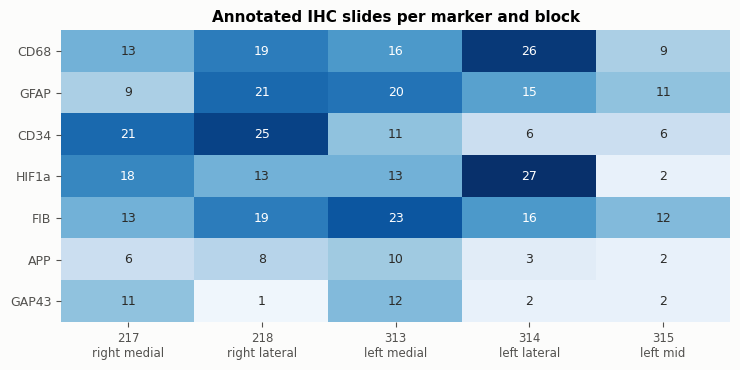

In [7]:
counts = catalog.markers(annotated=True)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.imshow(counts.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(counts.shape[1]), [f"{b}\n{BLOCKS[b]}" for b in counts.columns], fontsize=8.5)
ax.set_yticks(range(counts.shape[0]), counts.index)
for (r, c), v in np.ndenumerate(counts.values):
    ax.text(c, r, v, ha="center", va="center", fontsize=9, color="white" if v > counts.values.max() * 0.55 else "#2b2b29")
ax.spines[:].set_visible(False)
ax.set_title("Annotated IHC slides per marker and block")
plt.tight_layout()
plt.show()

## 3. Finding slides

`find()` filters slides by block, stain, marker and annotation status. `get_section_numbers()` returns the sorted section numbers directly. `get_slide()` returns the catalogue row of one slide.

In [8]:
gfap_313 = catalog.get_section_numbers(block=313, stain="IHC", marker="GFAP", annotated=True)
print(f"{len(gfap_313)} annotated GFAP sections in block 313, e.g. {gfap_313[:6]}")

catalog.find(block=313, stain="HE", annotated=True).head(3)

20 annotated GFAP sections in block 313, e.g. [167, 575, 605, 713, 761, 875]


,block,section,stain,marker,path,annotation_url,annotation_type,z_mm,global_id
0,313,368,HE,None,/stroke2d/storageIIT/580/HEOS/B_580_HB2CV[LM]-...,https://c-stroke.humanbrain.in/histology_detec...,HE,81.40,4070
1,313,398,HE,None,/stroke2d/storageIIT/580/HEOS/B_580_HB2CV[LM]-...,https://c-stroke.humanbrain.in/histology_detec...,HE,80.80,4040
2,313,416,HE,None,/stroke2d/storageIIT/580/HEOS/B_580_HB2CV[LM]-...,https://c-stroke.humanbrain.in/histology_detec...,HE,80.44,4022


### 3.1 Sets and neighbours

A set groups the sections that the platform shows together. `get_set()` lists them with their offset from the IHC section. `neighbours()` goes further: for any section it finds the nearest slide of *every* stain, and of every IHC marker, in the same block. That is the starting point for any cross-stain comparison.

In [9]:
example = catalog.get_set(EXAMPLE_SET)
example[["set_id", "block", "stain", "marker", "section", "offset_mm", "annotation_type"]]

,set_id,block,stain,marker,section,offset_mm,annotation_type
0,170,313,IHC,FIB,1331,0.00,FIB
1,170,313,N,None,1330,0.02,None
2,170,313,HE,None,1328,0.06,HE
3,170,313,M,None,1332,-0.02,None


In [10]:
block, section = int(example.block.iloc[0]), int(example.section.iloc[0])
near = catalog.neighbours(block, section, max_gap=60)
near[["stain", "marker", "section", "gap_sections", "distance_um", "annotation_type"]]

,stain,marker,section,gap_sections,distance_um,annotation_type
0,IHC,FIB,1331,0,0,FIB
1,M,None,1332,1,20,None
2,N,None,1330,-1,20,None
3,HE,None,1328,-3,60,HE
4,IHC,AQP4,1307,-24,480,None
5,IHC,GFAP,1373,42,840,GFAP
6,IHC,CD68,1379,48,960,CD68


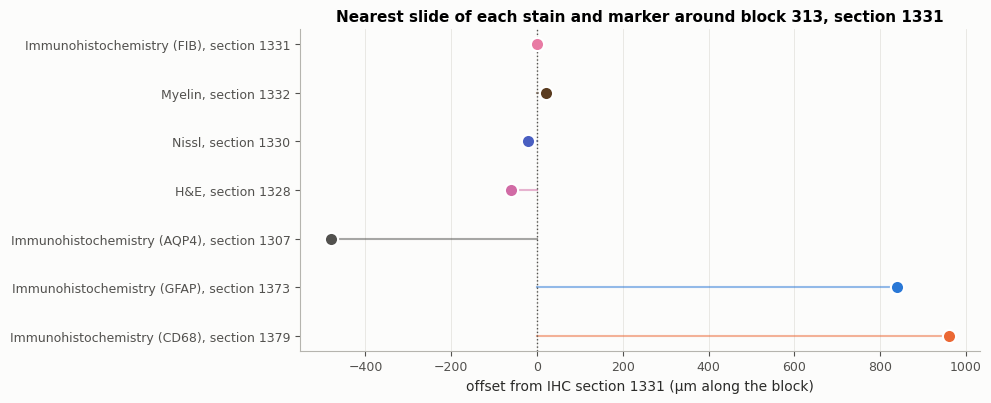

In [11]:
fig, ax = plt.subplots(figsize=(10, 0.42 * len(near) + 1.2))
for y, (_, r) in enumerate(near.iterrows()):
    color = du.MARKER_COLORS.get(r.marker, "#52514e") if r.stain == "IHC" else du.STAIN_COLORS[r.stain]
    ax.plot([0, r.gap_sections * 20], [y, y], color=color, lw=1.5, alpha=0.5)
    ax.scatter(r.gap_sections * 20, y, s=90, color=color, edgecolor="white", lw=1.5, zorder=3)
ax.set_yticks(range(len(near)), [f"{STAINS[r.stain]}" + (f" ({r.marker})" if r.marker else "") + f", section {r.section}"
                                 for _, r in near.iterrows()])
ax.invert_yaxis()
ax.axvline(0, color="#52514e", lw=1, ls=":")
ax.grid(axis="x")
ax.set_xlabel(f"offset from IHC section {section} (µm along the block)")
ax.set_title(f"Nearest slide of each stain and marker around block {block}, section {section}")
plt.tight_layout()
plt.show()

## 4. Whole-slide images

`SlideHelper(block, stain, downsample)` reads images of one block and stain from the platform's image server. Images are pyramids with eight levels. `downsample` selects the level: an image at `downsample = d` has 2^d full-resolution pixels per pixel. At the full resolution of about 1 µm per pixel, a whole section is up to 160,000 pixels (16 cm) wide, so whole sections are read at a coarse level and details at a fine one.

In [12]:
nissl = SlideHelper(block, "N", downsample=6, catalog=catalog)
print(nissl)
nissl.get_levels(int(example[example.stain == "N"].section.iloc[0]))

SlideHelper(block=313 [left medial], stain=N [Nissl], 67 sections, downsample=6 (~64 um/px))


,downsample,width_px,height_px,um_per_px
0,0,192000,192000,1.0
1,1,96000,96000,2.0
2,2,48000,48000,4.0
3,3,24000,24000,8.0
4,4,12000,12000,16.0
5,5,6000,6000,32.0
6,6,3000,3000,64.0
7,7,1500,1500,128.0


### 4.1 A whole section

`get_sectionimage(section)` returns the tissue area of a section as an RGB array, together with a `Region`. The `Region` records where the image lies on the canvas (`x0`, `y0`) and how many canvas pixels each image pixel covers (`scale`). Everything that follows (annotations, fields of view, scale bars) uses it to convert between image pixels and canvas coordinates.

image (1486, 2662, 3) | region Region(x0=432.0, y0=53680.0, scale=64.0, shape=(1486, 2662)) | 64 um per pixel


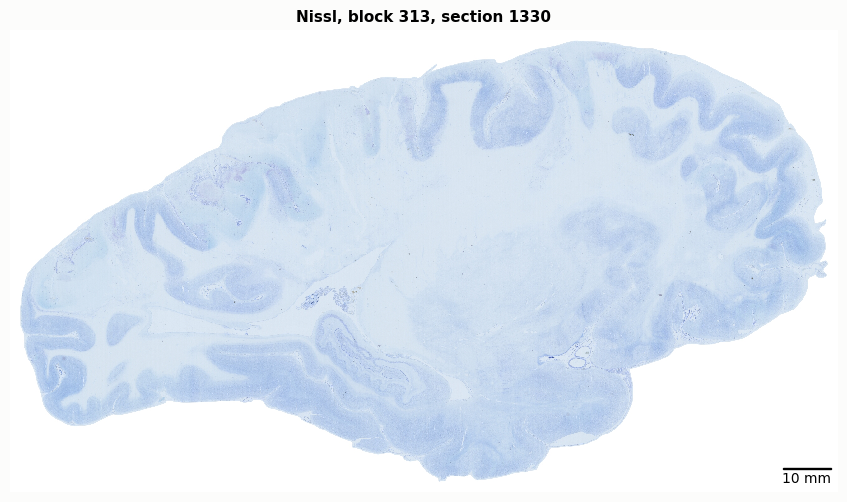

In [13]:
nissl_section = int(example[example.stain == "N"].section.iloc[0])
image, region = nissl.get_sectionimage(nissl_section)
print("image", image.shape, "| region", region, f"| {region.mpp:.0f} um per pixel")

fig, ax = plt.subplots(figsize=(12, 6))
du.show_image(ax, image, region, f"Nissl, block {block}, section {nissl_section}", bar_mm=10)
plt.show()

### 4.2 The four stains of a set

Because the stains share one canvas, a single bounding box can cut the same area out of every slide of the set. The annotations drawn on them are introduced in `pathology_annotations.ipynb`. Here they show the H&E infarct outline and the fibrinogen regions on the IHC slide.

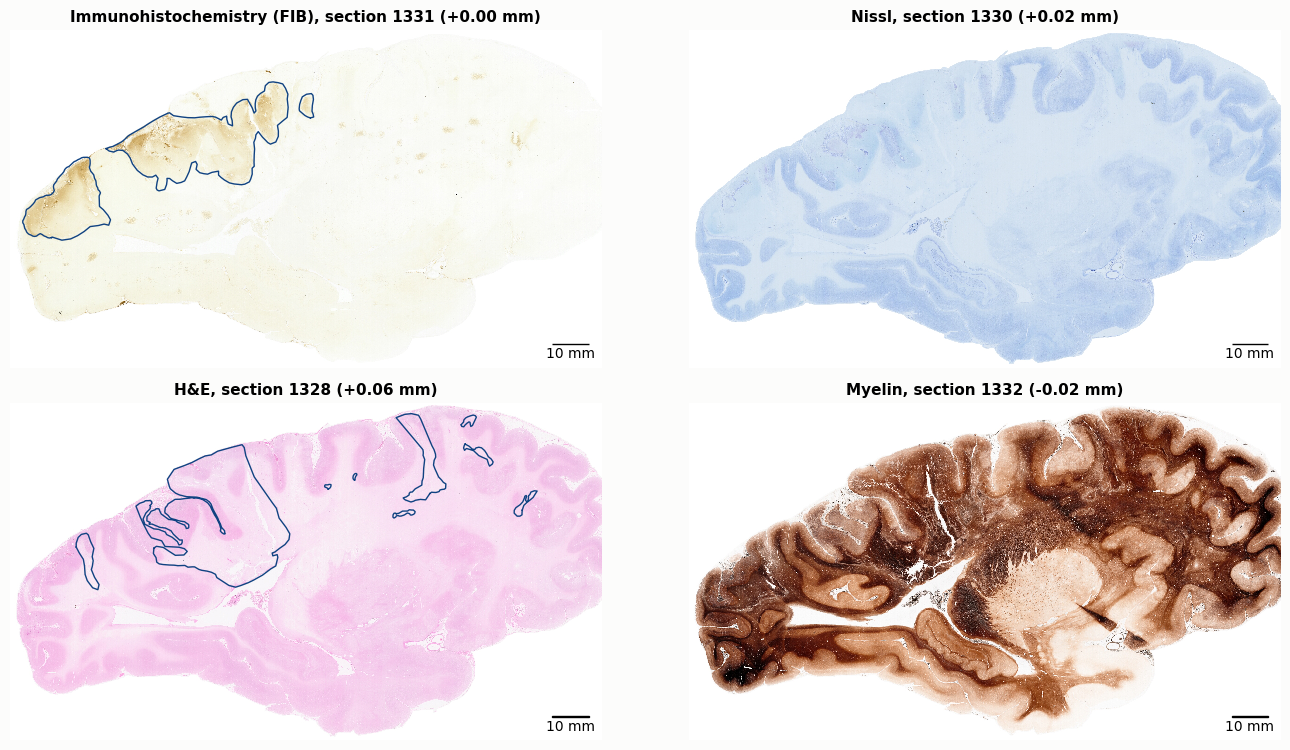

In [14]:
bbox = SlideHelper(block, "IHC", catalog=catalog).get_tissue_bbox(section)
fig, axes = plt.subplots(2, 2, figsize=(14, 7.6))
for ax, (_, r) in zip(axes.ravel(), example.iterrows()):
    helper = SlideHelper(r.block, r.stain, downsample=6, catalog=catalog)
    img, reg = helper.get_region(r.section, *bbox)
    title = f"{STAINS[r.stain]}{' (' + r.marker + ')' if r.marker else ''}, section {r.section} ({r.offset_mm:+.2f} mm)"
    du.show_image(ax, img, reg, title, bar_mm=10)
    annotation = helper.get_annotation(r.section)
    if annotation is not None:
        du.draw_annotation(ax, annotation, reg, linewidth=1.0)
plt.tight_layout()
plt.show()

### 4.3 From overview to cellular detail

`get_field(section, center, size_um, downsample)` reads a square field of view around a canvas point. The field below is centred on a point of the infarct border (red line, drawn from the H&E annotation of the same set) that is surrounded by tissue. The same 2 mm field is shown at four pyramid levels: 64, 16, 4 and 1 µm per pixel. Individual cells are resolved only at the finest levels, which is where cell-level analyses must be done.

field centre: x = 57956, y = 87545 canvas pixels


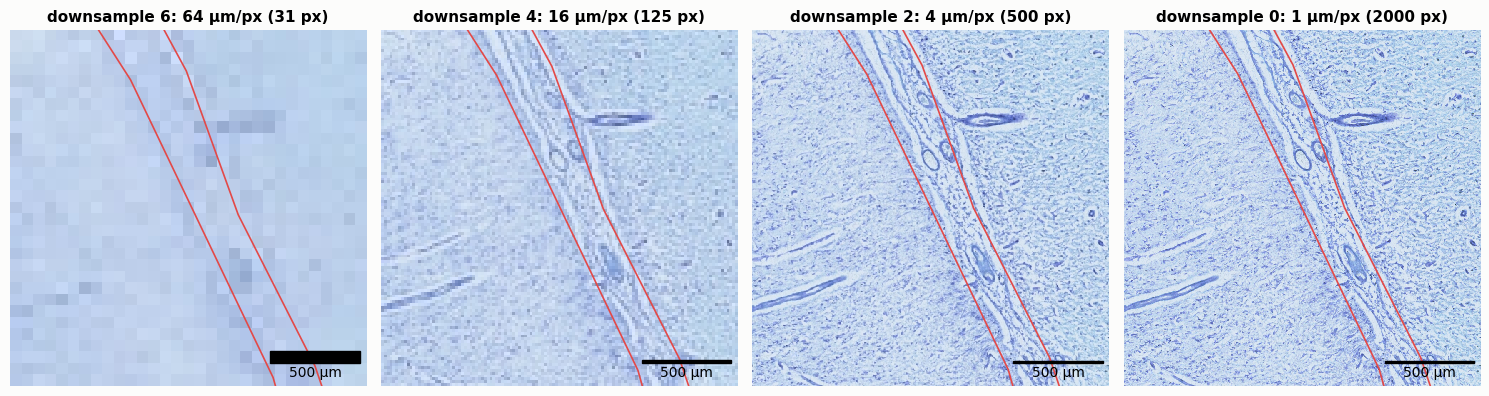

In [15]:
he_annotation = SlideHelper(block, "HE", catalog=catalog).get_annotation(int(example[example.stain == "HE"].section.iloc[0]))

# Choose a point on the infarct border that is surrounded by tissue on both sides: sample the border of the largest
# infarct polygon and keep the point with the highest tissue fraction within 1 mm on the Nissl overview.
tissue = ndi.uniform_filter(tissue_mask(image).astype(float), size=int(2000 / region.mpp))
border = max((r["geometry"] for r in he_annotation.records), key=lambda g: g.area).exterior
candidates = [border.interpolate(t, normalized=True) for t in np.linspace(0, 1, 400, endpoint=False)]
cols, rows = region.to_pixels([p.x for p in candidates], [p.y for p in candidates])
inside_image = (rows >= 0) & (rows < image.shape[0]) & (cols >= 0) & (cols < image.shape[1])
score = np.where(inside_image, tissue[np.clip(rows.astype(int), 0, image.shape[0] - 1),
                                      np.clip(cols.astype(int), 0, image.shape[1] - 1)], -1)
best = candidates[int(np.argmax(score))]
center = (best.x, best.y)                          # canvas pixels
print(f"field centre: x = {center[0]:.0f}, y = {center[1]:.0f} canvas pixels")

fig, axes = plt.subplots(1, 4, figsize=(15, 4.1))
for ax, d in zip(axes, (6, 4, 2, 0)):
    img, reg = nissl.get_field(nissl_section, center, 2000, downsample=d)
    du.show_image(ax, img, reg, f"downsample {d}: {reg.mpp:g} µm/px ({img.shape[1]} px)", bar_mm=0.5)
    du.draw_annotation(ax, he_annotation, reg, colors={1: du.INFARCT_COLOR}, linewidth=1.2)
plt.tight_layout()
plt.show()

## 5. One location across the stains

The registration across stains is what makes C-Stroke more than a collection of slides: a lesion seen on one stain can be examined on all the others. The figure shows the field from Section 4.3 on all four sections of the set, at 4 mm and at 500 µm, with the H&E infarct border in red. The neighbouring sections are 20–60 µm apart, so tissue structures line up but individual cells differ.

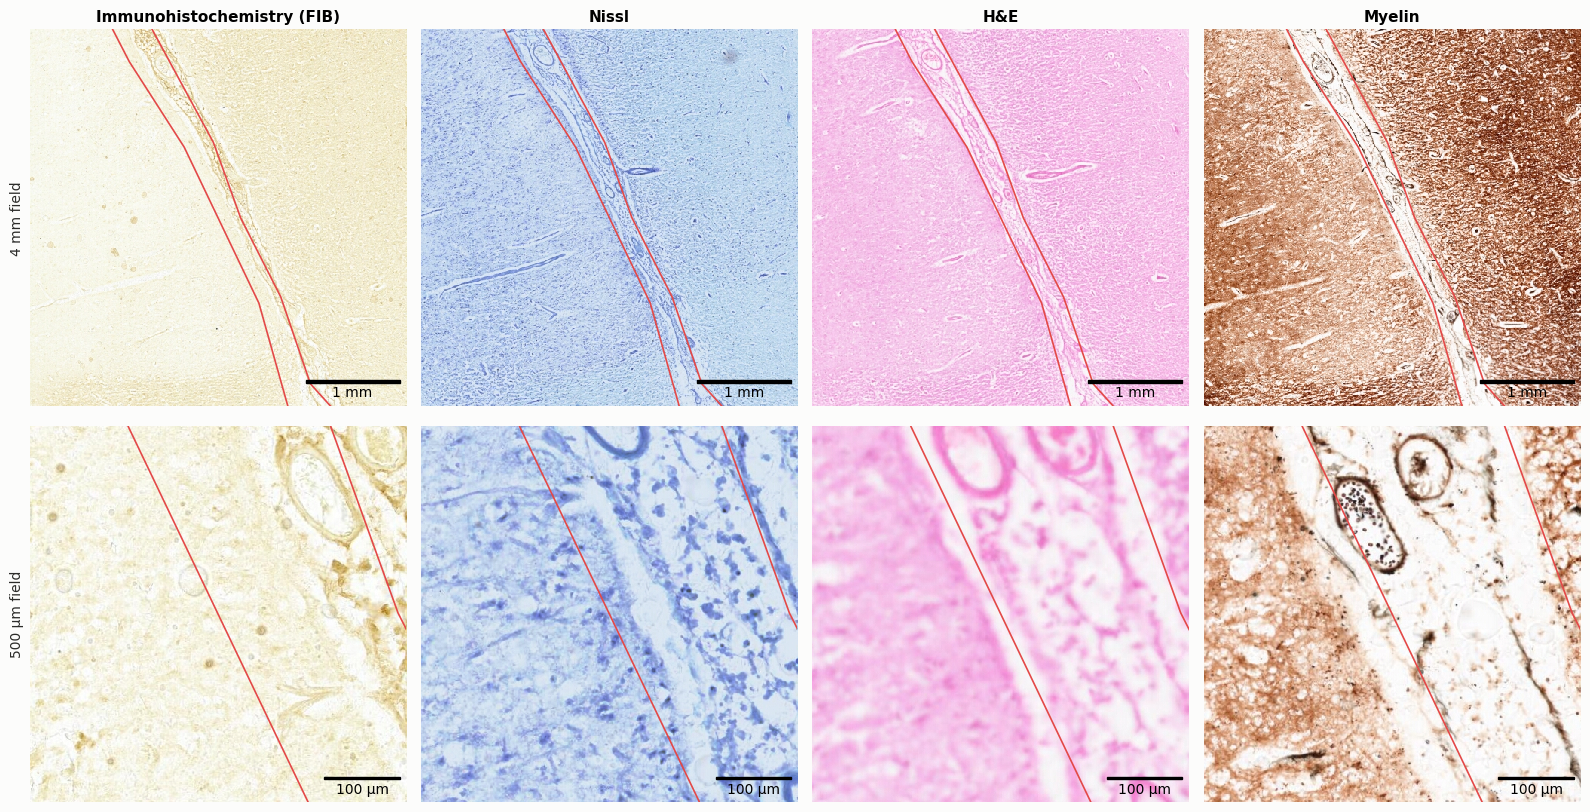

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8.4))
for c, (_, r) in enumerate(example.iterrows()):
    helper = SlideHelper(r.block, r.stain, catalog=catalog)
    for row, (size_um, d, bar) in enumerate([(4000, 3, 1), (500, 0, 0.1)]):
        img, reg = helper.get_field(r.section, center, size_um, downsample=d)
        du.show_image(axes[row, c], img, reg, bar_mm=bar,
                      title=(f"{STAINS[r.stain]}{' (' + r.marker + ')' if r.marker else ''}" if row == 0 else None))
        du.draw_annotation(axes[row, c], he_annotation, reg, colors={1: du.INFARCT_COLOR}, linewidth=1.2)
axes[0, 0].set_ylabel("4 mm field", fontsize=10)
axes[1, 0].set_ylabel("500 µm field", fontsize=10)
plt.tight_layout()
plt.show()

The four stains show complementary aspects of the same tissue. Fibrinogen (IHC) marks plasma protein that has leaked through a damaged blood–brain barrier. Nissl shows neuronal and glial cell bodies, H&E the general tissue texture, and the myelin stain the density of myelinated fibres. Comparing the two sides of the border on each stain is the basic step of a radiology–pathology or cross-marker study. `pathology_annotations.ipynb` and `lesion_across_sections.ipynb` turn this comparison into measurements.

*To explore:* set `EXAMPLE_SET` to another set (for example `164` for GFAP or `56` for CD68) and re-run from Section 3.1.

## 6. Block-face photographs

Before each section was cut, the exposed face of the frozen block was photographed. These **block-face images** show the tissue undistorted by cutting, mounting and staining, which makes them a reference for checking the shape of a section and for 3D reconstruction. `get_blockface(section)` returns the photograph for a section, or that of the nearest section that has one.

block-face photograph of section 1330: 3188 x 2176 px


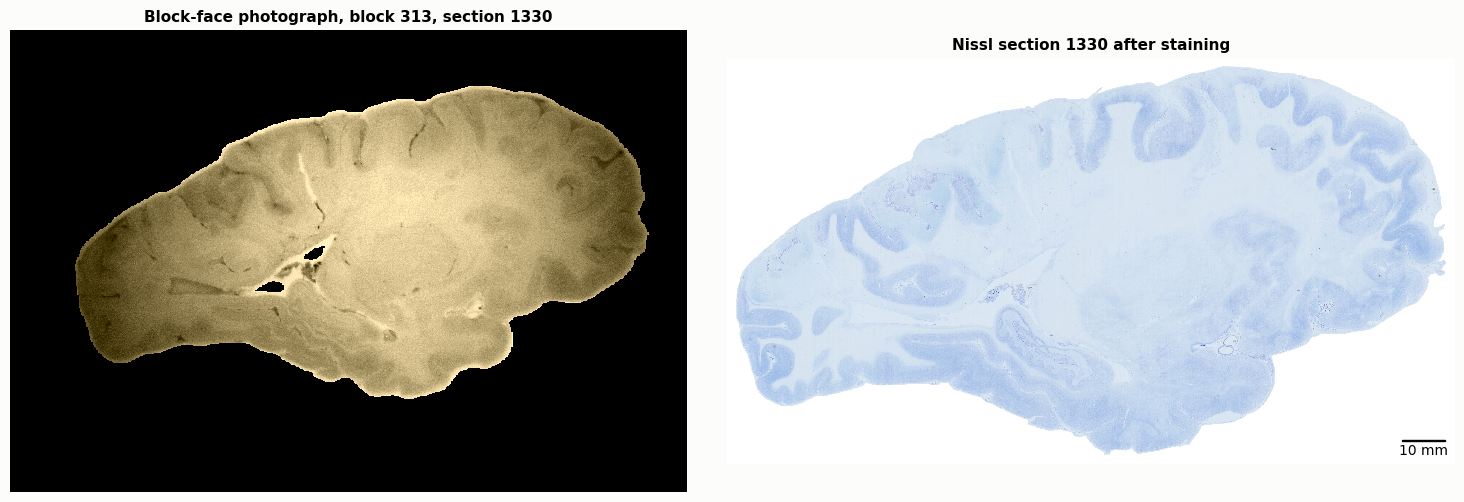

In [17]:
blockface, used = nissl.get_blockface(nissl_section)
print(f"block-face photograph of section {used}: {blockface.shape[1]} x {blockface.shape[0]} px")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].imshow(blockface)
axes[0].set_title(f"Block-face photograph, block {block}, section {used}")
du.show_image(axes[1], image, region, f"Nissl section {nissl_section} after staining", bar_mm=10)
axes[0].axis("off")
plt.tight_layout()
plt.show()

## 7. Tiles for analysis

Image analysis and machine-learning pipelines usually work on fixed-size tiles. `iter_tiles(section, tile_px, downsample, min_tissue)` yields `(tile, x0, y0)` for every tile that contains enough tissue. The canvas position is returned with each tile so results can be mapped back onto the slide. Tiles are read in blocks of 8 × 8 per request, which is much faster than requesting them one by one.

Below: the section cut into 4 mm tiles at 16 µm per pixel, with the tile positions on the section and six example tiles.

626 tiles of 250 x 250 px (4 mm) with at least 60% tissue


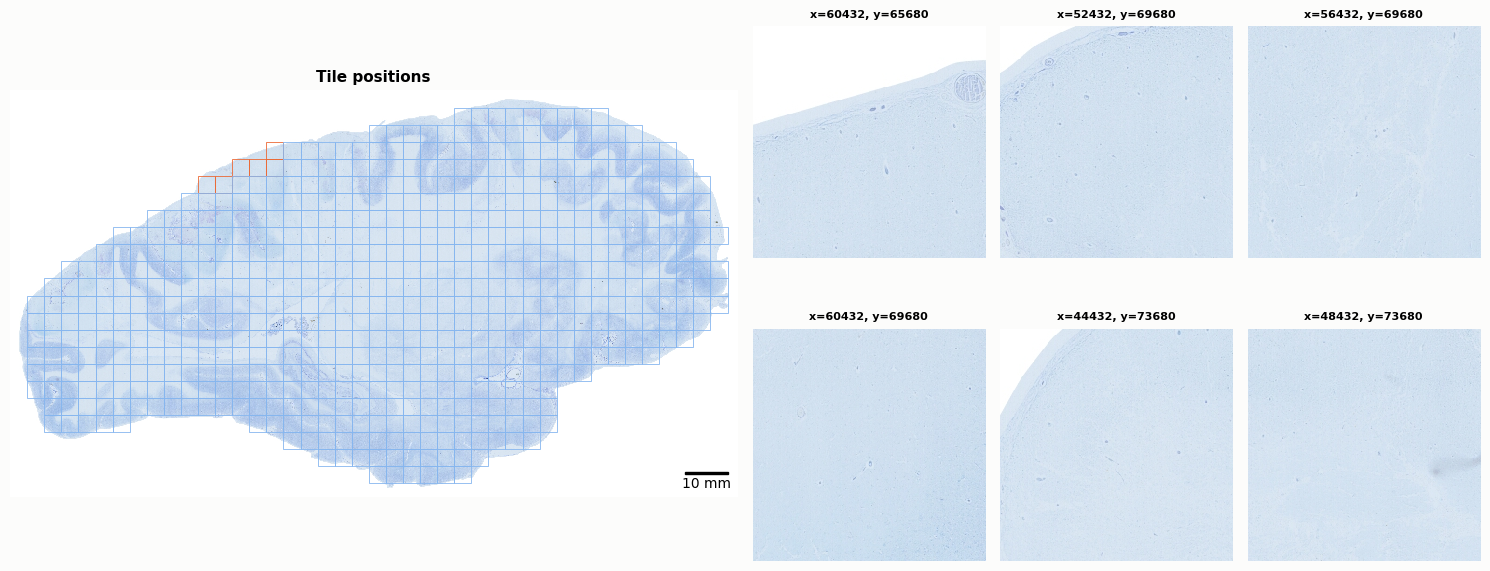

(626, 250, 250, 3)

In [18]:
tiles = list(nissl.iter_tiles(nissl_section, tile_px=250, downsample=4, min_tissue=0.6))
print(f"{len(tiles)} tiles of 250 x 250 px ({250 * 2 ** 4 * MPP_LEVEL0 / 1000:.0f} mm) with at least 60% tissue")

fig = plt.figure(figsize=(15, 6.2))
grid = fig.add_gridspec(2, 6, width_ratios=[1, 1, 1, 1, 1, 1])
ax_map = fig.add_subplot(grid[:, :3])
du.show_image(ax_map, image, region, "Tile positions", bar_mm=10)
for k, (tile, x0, y0) in enumerate(tiles):
    c, r = region.to_pixels(x0, y0)
    size = 250 * 2 ** 4 / region.scale
    ax_map.add_patch(plt.Rectangle((c, r), size, size, fill=False, lw=0.6,
                                   ec="#eb6834" if k < 6 else "#86b6ef"))
for k in range(6):
    ax = fig.add_subplot(grid[k // 3, 3 + k % 3])
    ax.imshow(tiles[k][0])
    ax.set_title(f"x={tiles[k][1]:.0f}, y={tiles[k][2]:.0f}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

tile_stack = np.stack([t for t, _, _ in tiles])      # (n, 250, 250, 3) uint8, ready for numpy / PyTorch
tile_stack.shape

## 8. A download table

`to_listing()` returns one row per slide with the URLs needed to use the data outside Python:

* `thumbnail_url`: a 2,048 px overview of the whole canvas;
* `zoomify_url`: the pyramid description for zoomable viewers;
* `annotation_url`: the annotation file, if any;
* `blockface_url`: the block-face photograph.

Saved as CSV, the table can be filtered in a spreadsheet or used for batch downloads.

In [19]:
listing = catalog.to_listing(block=block)
listing.to_csv(f"cstroke_slides_block_{block}.csv", index=False)
print(f"{len(listing)} slides of block {block} written to cstroke_slides_block_{block}.csv")
listing.head(4)

278 slides of block 313 written to cstroke_slides_block_313.csv


,block,stain,section,marker,z_mm,global_id,path,thumbnail_url,zoomify_url,annotation_url,annotation_type,blockface_url
0,313,HE,56,None,87.64,4382,/stroke2d/storageIIT/580/HEOS/B_580_HB2CV[LM]-...,https://c-stroke.humanbrain.in/fcgi-bin/iipsrv...,https://c-stroke.humanbrain.in/fcgi-bin/iipsrv...,None,None,https://c-stroke.humanbrain.in/Stroke_BFIW/313...
1,313,HE,152,None,85.72,4286,/stroke2d/storageIIT/580/HEOS/B_580_HB2CV[LM]-...,https://c-stroke.humanbrain.in/fcgi-bin/iipsrv...,https://c-stroke.humanbrain.in/fcgi-bin/iipsrv...,None,None,https://c-stroke.humanbrain.in/Stroke_BFIW/313...
2,313,HE,164,None,85.48,4274,/stroke2d/storageIIT/580/HEOS/B_580_HB2CV[LM]-...,https://c-stroke.humanbrain.in/fcgi-bin/iipsrv...,https://c-stroke.humanbrain.in/fcgi-bin/iipsrv...,None,None,https://c-stroke.humanbrain.in/Stroke_BFIW/313...
3,313,HE,200,None,84.76,4238,/stroke2d/storageIIT/580/HEOS/B_580_HB2CV[LM]-...,https://c-stroke.humanbrain.in/fcgi-bin/iipsrv...,https://c-stroke.humanbrain.in/fcgi-bin/iipsrv...,None,None,https://c-stroke.humanbrain.in/Stroke_BFIW/313...


## Summary

| Task | Call |
|---|---|
| Blocks, stains and annotation coverage | `catalog.summary()`, `catalog.markers(annotated=True)` |
| Slides of a block, stain and marker | `catalog.find(...)`, `catalog.get_section_numbers(...)` |
| The sections shown together on the platform | `catalog.get_set(set_id)` |
| Nearest slide of every stain and marker | `catalog.neighbours(block, section)` |
| Pyramid levels of a slide | `SlideHelper(block, stain).get_levels(section)` |
| Whole section, region, field of view | `get_sectionimage`, `get_region`, `get_field` |
| Block-face photograph | `get_blockface(section)` |
| Tiles with canvas positions | `iter_tiles(section, tile_px, downsample, min_tissue)` |
| URLs for download | `catalog.to_listing(block)` |

**Notes.** Physical units use 1.0 µm per full-resolution pixel. The value is not stored with the images; `slide_utils` derives it from the C-Stroke reference space, where section areas measured on the slides match the same planes in the ex-vivo MRI to within a few per cent. Sections of different stains are 20–60 µm apart, so registration aligns tissue structures, not individual cells.

**Next:** `pathology_annotations.ipynb` shows how to load, measure and rasterise the expert annotations drawn on these slides.